In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../dataset/insurance.csv")

# Display first 10 rows
print(df.head(10))

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
5   31  female  25.740         0     no  southeast   3756.62160
6   46  female  33.440         1     no  southeast   8240.58960
7   37  female  27.740         3     no  northwest   7281.50560
8   37    male  29.830         2     no  northeast   6406.41070
9   60  female  25.840         0     no  northwest  28923.13692


In [2]:
# Display last 5 rows
print(df.tail())

# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column information
print(df.info())

# Statistical summary
print(df.describe())

      age     sex    bmi  children smoker     region     charges
1333   50    male  30.97         3     no  northwest  10600.5483
1334   18  female  31.92         0     no  northeast   2205.9808
1335   18  female  36.85         0     no  southeast   1629.8335
1336   21  female  25.80         0     no  southwest   2007.9450
1337   61  female  29.07         0    yes  northwest  29141.3603
Dataset Shape: (1338, 7)
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB
None
               age          bmi     children       charges
count  1338.0000

In [3]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# Check column names
print("\nColumns:", df.columns.tolist())

# Check data types
print("\nData Types:")
print(df.dtypes)

# Check unique values in categorical columns
categorical_columns = ["sex", "smoker", "region"]

for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts())

Missing Values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate Rows: 1

Columns: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']

Data Types:
age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

sex:
sex
male      676
female    662
Name: count, dtype: int64

smoker:
smoker
no     1064
yes     274
Name: count, dtype: int64

region:
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


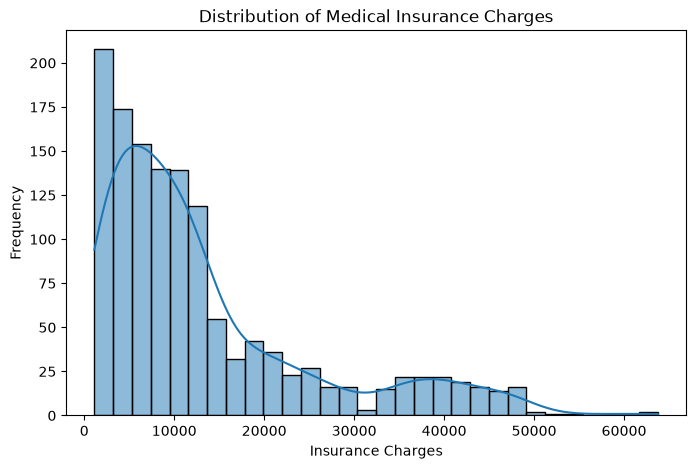

In [4]:
plt.figure(figsize=(8, 5))

sns.histplot(df["charges"], kde=True)

plt.title("Distribution of Medical Insurance Charges")
plt.xlabel("Insurance Charges")
plt.ylabel("Frequency")

plt.show()

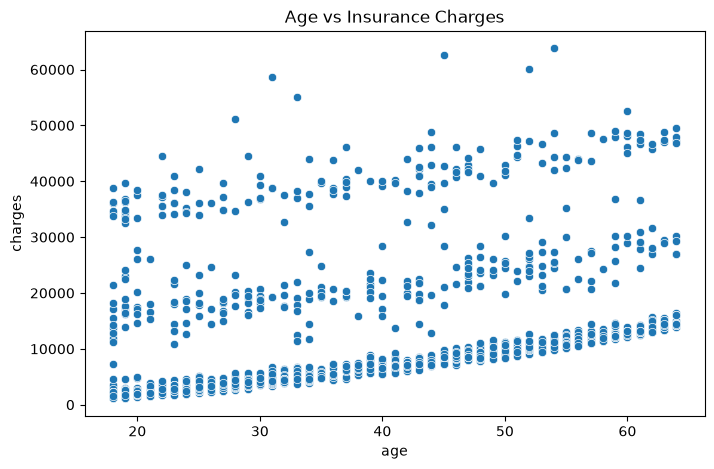

In [5]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="age", y="charges")

plt.title("Age vs Insurance Charges")
plt.show()

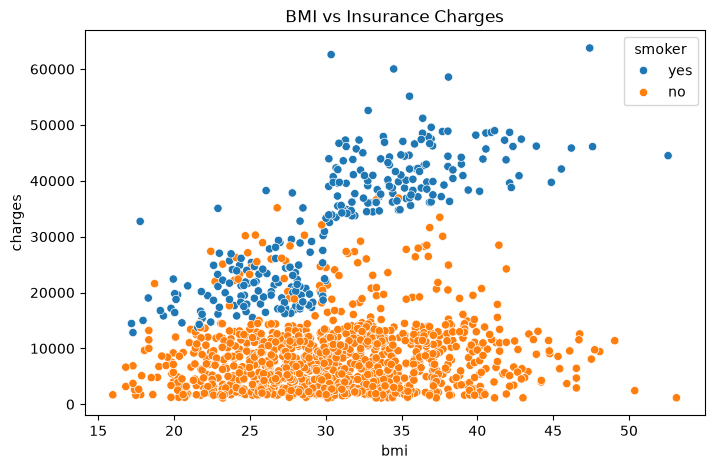

In [6]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="bmi",
    y="charges",
    hue="smoker"
)

plt.title("BMI vs Insurance Charges")
plt.show()

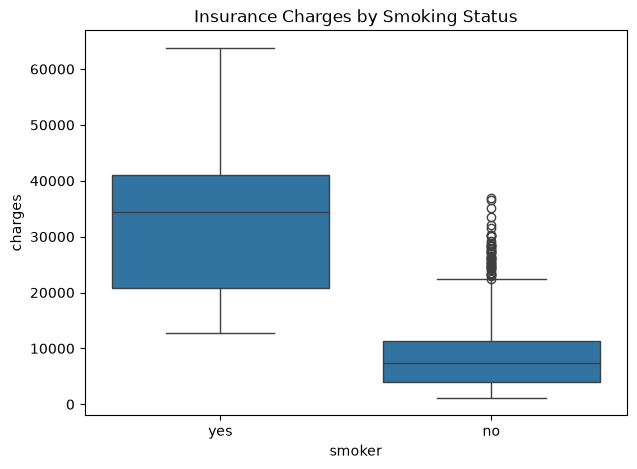

In [7]:
plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x="smoker", y="charges")

plt.title("Insurance Charges by Smoking Status")
plt.show()

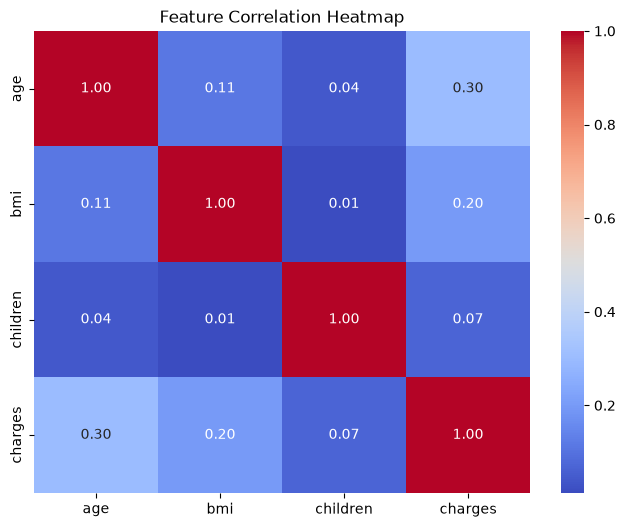

In [8]:
# Select numerical columns
numerical_df = df.select_dtypes(include=np.number)

# Correlation matrix
correlation = numerical_df.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [9]:
duplicates = df[df.duplicated(keep=False)]

print(duplicates)

     age   sex    bmi  children smoker     region    charges
195   19  male  30.59         0     no  northwest  1639.5631
581   19  male  30.59         0     no  northwest  1639.5631


In [10]:
numerical_columns = ["age", "bmi", "children", "charges"]

for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"\n{col.upper()}")
    print("Lower Bound:", round(lower, 2))
    print("Upper Bound:", round(upper, 2))
    print("Outlier Count:", len(outliers))


AGE
Lower Bound: -9.0
Upper Bound: 87.0
Outlier Count: 0

BMI
Lower Bound: 13.7
Upper Bound: 47.29
Outlier Count: 9

CHILDREN
Lower Bound: -3.0
Upper Bound: 5.0
Outlier Count: 0

CHARGES
Lower Bound: -13109.15
Upper Bound: 34489.35
Outlier Count: 139


In [11]:
# Create a copy of the original dataset
df_clean = df.copy()

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Reset index
df_clean = df_clean.reset_index(drop=True)

print("Original Shape:", df.shape)
print("Cleaned Shape:", df_clean.shape)

print("Remaining Duplicates:", df_clean.duplicated().sum())

Original Shape: (1338, 7)
Cleaned Shape: (1337, 7)
Remaining Duplicates: 0


In [12]:
Q1 = df_clean["bmi"].quantile(0.25)
Q3 = df_clean["bmi"].quantile(0.75)

IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

bmi_outliers = df_clean[df_clean["bmi"] > upper_bound]

print("BMI Upper Bound:", upper_bound)
print("\nBMI Outlier Records:")
print(bmi_outliers[["age", "bmi", "smoker", "charges"]])

BMI Upper Bound: 47.31500000000001

BMI Outlier Records:
      age    bmi smoker      charges
116    58  49.06     no  11381.32540
286    46  48.07     no   9432.92530
401    47  47.52     no   8083.91980
543    54  47.41    yes  63770.42801
846    23  50.38     no   2438.05520
859    37  47.60    yes  46113.51100
1046   22  52.58    yes  44501.39820
1087   52  47.74     no   9748.91060
1316   18  53.13     no   1163.46270


In [13]:
Q1 = df_clean["charges"].quantile(0.25)
Q3 = df_clean["charges"].quantile(0.75)

IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

charge_outliers = df_clean[df_clean["charges"] > upper_bound]

print("Charges Upper Bound:", upper_bound)

print("\nOutliers by Smoking Status:")
print(charge_outliers["smoker"].value_counts())

print("\nAverage Charges by Smoking Status:")
print(df_clean.groupby("smoker")["charges"].mean())

Charges Upper Bound: 34524.777625

Outliers by Smoking Status:
smoker
yes    136
no       3
Name: count, dtype: int64

Average Charges by Smoking Status:
smoker
no      8440.660307
yes    32050.231832
Name: charges, dtype: float64


In [14]:
# Check missing values
print("Missing Values:")
print(df_clean.isnull().sum())

# Check duplicates
print("\nDuplicates:", df_clean.duplicated().sum())

# Check final shape
print("\nFinal Dataset Shape:", df_clean.shape)

# Save cleaned dataset
df_clean.to_csv("../dataset/insurance_cleaned.csv", index=False)

print("\nCleaned dataset saved successfully!")

Missing Values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicates: 0

Final Dataset Shape: (1337, 7)

Cleaned dataset saved successfully!
